# Fase 4 — Funciones de pérdida y métricas
**Corre en CPU** (no necesita GPU). Prepara las piezas de los entregables 2(b) y 3, y calcula la **línea base de Otsu** con exactamente las mismas métricas que usará la U-Net.

## Teoría
Sea $p_i = \sigma(z_i)$ la probabilidad de agua del píxel $i$ (sigmoide del logit) y $y_i \in \{0,1\}$ la etiqueta. **Solo se suman los píxeles válidos** ($y_i \neq -1$).

**BCE (entropía cruzada binaria):**
$$\mathcal{L}_{BCE} = -\frac{1}{N}\sum_i \big[y_i \log p_i + (1-y_i)\log(1-p_i)\big]$$
Promedia el error de *cada píxel*. Con ~9 % de agua, el 91 % de los términos son "no agua": la red puede bajar mucho la pérdida ignorando el agua.

**Dice suave:**
$$\mathcal{L}_{Dice} = 1 - \frac{2\sum_i p_i y_i + s}{\sum_i p_i + \sum_i y_i + s}$$
Es 1 − (superposición de la clase agua). El fondo no aparece en el numerador → **no lo domina el desbalance**. Está emparentado con el F1 (y con el IoU), es decir, optimiza algo muy cercano a lo que evaluamos. Contra: gradientes más ruidosos.

**Combinada:** $0.5\,\mathcal{L}_{BCE} + 0.5\,\mathcal{L}_{Dice}$ — práctica muy común en segmentación médica y de teledetección.

**Métricas (clase agua), con VP/FP/FN/VN sumados sobre TODOS los chips:**
- IoU = VP / (VP + FP + FN) · F1 = 2·P·R / (P + R) · Precisión = VP / (VP + FP) · Recall = VP / (VP + FN)
- Omisión = 1 − Recall (agua perdida) · Comisión = 1 − Precisión (agua inventada) — las que reportan los autores de Sen1Floods11.
- **IoU agregado vs. promedio por chip:** sumamos conteos antes de dividir. Así los chips sin agua (26 en Ghana) no producen 0/0 y cada píxel pesa igual.

## 0. Preparación (puede ser sin GPU)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
from pathlib import Path
RAIZ_PROYECTO = Path('/content/drive/MyDrive/rnap_p2_inundaciones')
sys.path.insert(0, str(RAIZ_PROYECTO))

!pip install -q rasterio

Mounted at /content/drive


## 1. Módulos nuevos

In [2]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/perdidas.py
"""
perdidas.py
Funciones de pérdida para segmentación binaria con píxeles a IGNORAR (etiqueta = -1).
Todas reciben:
  logits    : (B, 1, H, W) o (B, H, W)  -> salida cruda de la U-Net (sin sigmoide)
  etiquetas : (B, H, W) int64           -> 0 no agua, 1 agua, -1 ignorar
Las tres opciones son las de la ablación (b): BCE vs Dice vs combinada.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

VALOR_IGNORAR = -1


def _aplanar_validos(logits, etiquetas):
    if logits.dim() == 4:
        logits = logits.squeeze(1)
    validos = etiquetas != VALOR_IGNORAR
    return logits[validos], (etiquetas[validos] == 1).float()


class PerdidaBCE(nn.Module):
    """Entropía cruzada binaria por píxel.
    + Gradientes estables y bien comportados desde el inicio.
    - Cada píxel pesa igual: con ~9 % de agua, la red puede 'ganar' prediciendo casi todo no-agua.
    peso_positivo > 1 compensa ese desbalance multiplicando el error en píxeles de agua."""

    def __init__(self, peso_positivo: float | None = None):
        super().__init__()
        self.peso_positivo = peso_positivo

    def forward(self, logits, etiquetas):
        x, y = _aplanar_validos(logits, etiquetas)
        if x.numel() == 0:                       # lote sin píxeles válidos: pérdida 0 sin romper el grafo
            return logits.sum() * 0.0
        peso = None if self.peso_positivo is None else torch.tensor(self.peso_positivo, device=x.device)
        return F.binary_cross_entropy_with_logits(x, y, pos_weight=peso)


class PerdidaDice(nn.Module):
    """Pérdida Dice 'suave' (Milletari et al., 2016):  1 - 2·Σ(p·y) / (Σp + Σy)
    con p = sigmoide(logits) (probabilidades continuas, para que sea derivable).
    + Mide superposición de la CLASE AGUA: el fondo abundante no la domina -> robusta al desbalance.
    - Gradientes más ruidosos, sobre todo si el lote tiene poca agua.
    Se calcula sobre TODO el lote (no chip por chip): así un chip sin agua no produce 0/0."""

    def __init__(self, suavizado: float = 1.0):
        super().__init__()
        self.suavizado = suavizado

    def forward(self, logits, etiquetas):
        x, y = _aplanar_validos(logits, etiquetas)
        if x.numel() == 0:
            return logits.sum() * 0.0
        p = torch.sigmoid(x.float())             # float32 aunque se entrene con AMP (sumas grandes)
        interseccion = (p * y).sum()
        return 1 - (2 * interseccion + self.suavizado) / (p.sum() + y.sum() + self.suavizado)


class PerdidaCombinada(nn.Module):
    """peso_bce · BCE + peso_dice · Dice: estabilidad de la BCE + foco en la clase minoritaria del Dice."""

    def __init__(self, peso_bce: float = 0.5, peso_dice: float = 0.5, peso_positivo: float | None = None):
        super().__init__()
        self.peso_bce, self.peso_dice = peso_bce, peso_dice
        self.bce = PerdidaBCE(peso_positivo)
        self.dice = PerdidaDice()

    def forward(self, logits, etiquetas):
        return self.peso_bce * self.bce(logits, etiquetas) + self.peso_dice * self.dice(logits, etiquetas)


def crear_perdida(nombre: str, **parametros) -> nn.Module:
    """Fábrica para la ablación: crear_perdida('bce' | 'dice' | 'combinada')."""
    opciones = {"bce": PerdidaBCE, "dice": PerdidaDice, "combinada": PerdidaCombinada}
    if nombre not in opciones:
        raise ValueError(f"Pérdida desconocida '{nombre}'. Opciones: {list(opciones)}")
    return opciones[nombre](**parametros)


Writing /content/drive/MyDrive/rnap_p2_inundaciones/src/perdidas.py


In [3]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/metricas_torch.py
"""
metricas_torch.py
Acumulador de la matriz de confusión durante la evaluación (en GPU, sin copiar píxeles a CPU).
Clave: las métricas se calculan con los conteos SUMADOS de todos los chips (IoU agregado),
no promediando IoU chip por chip -> los chips sin agua (26 en Ghana) no producen 0/0.
También acumula por evento, para el desglose del informe.
"""
from collections import defaultdict

import numpy as np
import pandas as pd
import torch

from .metricas import metricas_desde_conteos

VALOR_IGNORAR = -1


class AcumuladorConfusion:
    def __init__(self, umbral: float = 0.5):
        self.umbral = umbral
        self.reiniciar()

    def reiniciar(self):
        self.global_ = torch.zeros(4, dtype=torch.int64)           # vp, fp, fn, vn
        self.por_evento = defaultdict(lambda: torch.zeros(4, dtype=torch.int64))

    @torch.no_grad()
    def actualizar(self, logits, etiquetas, ids_chips=None):
        if logits.dim() == 4:
            logits = logits.squeeze(1)
        prediccion = torch.sigmoid(logits.float()) > self.umbral
        referencia = etiquetas == 1
        validos = etiquetas != VALOR_IGNORAR
        # conteos por chip (dim 1,2 = alto, ancho) -> (B, 4)
        conteos = torch.stack([
            (prediccion & referencia & validos).sum(dim=(1, 2)),
            (prediccion & ~referencia & validos).sum(dim=(1, 2)),
            (~prediccion & referencia & validos).sum(dim=(1, 2)),
            (~prediccion & ~referencia & validos).sum(dim=(1, 2)),
        ], dim=1).cpu()
        self.global_ += conteos.sum(dim=0)
        if ids_chips is not None:
            for id_chip, fila in zip(ids_chips, conteos):
                self.por_evento[id_chip.split("_")[0]] += fila

    def metricas(self) -> dict:
        return metricas_desde_conteos(*self.global_.tolist())

    def matriz_confusion(self) -> np.ndarray:
        """[[VN, FP], [FN, VP]]  (filas = real no agua / agua; columnas = predicho no agua / agua)."""
        vp, fp, fn, vn = self.global_.tolist()
        return np.array([[vn, fp], [fn, vp]], dtype=np.int64)

    def tabla_por_evento(self) -> pd.DataFrame:
        filas = {evento: metricas_desde_conteos(*c.tolist()) for evento, c in self.por_evento.items()}
        return pd.DataFrame(filas).T.sort_values("iou")


Writing /content/drive/MyDrive/rnap_p2_inundaciones/src/metricas_torch.py


In [4]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/visualizacion_metricas.py
"""
visualizacion_metricas.py
Matriz de confusión comentable para el informe (entregable 3).
"""
import matplotlib.pyplot as plt
import numpy as np


def figura_matriz_confusion(matriz: np.ndarray, titulo: str = "", ruta_guardado=None):
    """matriz = [[VN, FP], [FN, VP]]. Muestra % por fila (cuánto de cada clase real se acierta) y conteos."""
    porcentajes = matriz / matriz.sum(axis=1, keepdims=True).clip(min=1)
    figura, eje = plt.subplots(figsize=(4.6, 4))
    eje.imshow(porcentajes, cmap="Blues", vmin=0, vmax=1)
    nombres = ["No agua", "Agua"]
    eje.set_xticks([0, 1], [f"Pred. {n}" for n in nombres])
    eje.set_yticks([0, 1], [f"Real {n}" for n in nombres])
    etiquetas = [["VN", "FP"], ["FN", "VP"]]
    for i in range(2):
        for j in range(2):
            color = "white" if porcentajes[i, j] > 0.5 else "black"
            eje.text(j, i, f"{etiquetas[i][j]}\n{100 * porcentajes[i, j]:.1f}%\n({matriz[i, j]:,} px)",
                     ha="center", va="center", color=color, fontsize=9)
    eje.set_title(titulo)
    figura.tight_layout()
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


Writing /content/drive/MyDrive/rnap_p2_inundaciones/src/visualizacion_metricas.py


In [5]:
import pandas as pd
import torch
from tqdm.auto import tqdm

from src.configuracion import *
from src.utilidades import fijar_semilla
from src.descarga import descargar_mano
from src.lectura import leer_particion, leer_otsu
from src.preprocesamiento import Normalizador
from src.conjunto_datos import ConjuntoInundaciones
from src.perdidas import crear_perdida
from src.metricas_torch import AcumuladorConfusion
from src.visualizacion_metricas import figura_matriz_confusion

fijar_semilla(SEMILLA)
descargar_mano()
normalizador = Normalizador.desde_json(DIR_RESULTADOS / 'f1_estadisticas_normalizacion.json')

[descargando] S1Hand ...
[descargando] LabelHand ...
[descargando] S1OtsuLabelHand ...
[descargando] flood_handlabeled ...


## 2. Pruebas unitarias de las pérdidas
Tres propiedades que **deben** cumplirse:
1. Predicción perfecta → pérdida ≈ 0.
2. Cambiar los logits de píxeles ignorados (−1) **no cambia** la pérdida.
3. El gradiente en píxeles ignorados es **exactamente 0** (la red no aprende de ellos).

In [6]:
torch.manual_seed(SEMILLA)
etiquetas = (torch.rand(4, 64, 64) > 0.9).long()
etiquetas[:, :10] = VALOR_SIN_DATO                     # una franja ignorada
logits = torch.randn(4, 1, 64, 64, requires_grad=True)
perfectos = torch.where(etiquetas == 1, 20.0, -20.0).unsqueeze(1)

filas = []
for nombre in ['bce', 'dice', 'combinada']:
    perdida = crear_perdida(nombre)
    valor = perdida(logits, etiquetas)
    logits.grad = None; valor.backward()
    alterados = logits.detach().clone(); alterados[:, 0][etiquetas == VALOR_SIN_DATO] = 99.0
    filas.append({'pérdida': nombre,
                  'valor aleatorio': round(valor.item(), 4),
                  '1) perfecto ≈ 0': round(perdida(perfectos, etiquetas).item(), 6),
                  '2) invariante a ignorados': bool(torch.isclose(perdida(alterados, etiquetas), valor)),
                  '3) gradiente 0 en ignorados': bool((logits.grad[:, 0][etiquetas == VALOR_SIN_DATO] == 0).all())})
pd.DataFrame(filas)

,pérdida,valor aleatorio,1) perfecto ≈ 0,2) invariante a ignorados,3) gradiente 0 en ignorados
0,bce,0.8009,0.0,True,True
1,dice,0.8298,0.0,True,True
2,combinada,0.8153,0.0,True,True


## 3. ¿Por qué el desbalance importa? Experimento con chips reales
Un "modelo" trivial que dice **siempre no agua** (con distintos grados de confianza), evaluado en la partición *valid*.

**Qué observar:** la **exactitud** sale altísima aunque el modelo es inútil (IoU = 0); la **BCE** puede ser baja si la confianza es moderada; el **Dice** queda ≈ 1 (máximo error) en todos los casos → *castiga* ignorar el agua.

In [7]:
conjunto_valid = ConjuntoInundaciones(leer_particion('valid')['id_chip'], normalizador, en_memoria=True)
etiquetas_valid = torch.stack([torch.from_numpy(etq) for _, etq in conjunto_valid.cache])

filas = []
for logit_constante in [-1.0, -2.0, -3.0, -5.0]:
    logits = torch.full((len(etiquetas_valid), 1, 512, 512), logit_constante)
    acumulador = AcumuladorConfusion(); acumulador.actualizar(logits, etiquetas_valid)
    m = acumulador.metricas()
    filas.append({'P(agua) predicha': round(torch.sigmoid(torch.tensor(logit_constante)).item(), 3),
                  'exactitud': round(m['exactitud'], 3), 'IoU agua': round(m['iou'], 3),
                  'BCE': round(crear_perdida('bce')(logits, etiquetas_valid).item(), 3),
                  'Dice': round(crear_perdida('dice')(logits, etiquetas_valid).item(), 3)})
pd.DataFrame(filas)

Cargando chips en RAM:   0%|          | 0/89 [00:00<?, ?it/s]

,P(agua) predicha,exactitud,IoU agua,BCE,Dice
0,0.269,0.89,0.0,0.423,0.844
1,0.119,0.89,0.0,0.347,0.886
2,0.047,0.89,0.0,0.379,0.934
3,0.007,0.89,0.0,0.557,0.987


## 4. Línea base: Otsu evaluado con NUESTRAS métricas
La U-Net tendrá que superar estos números **en las mismas particiones**. Se evalúa la etiqueta débil de Otsu como si fuera una predicción (logit +10 donde Otsu dice agua, −10 donde no). Se usa el mismo `ConjuntoInundaciones`, así que los píxeles ignorados son idénticos a los que verá la U-Net.

In [8]:
def evaluar_otsu(particion):
    ids = leer_particion(particion)['id_chip']
    conjunto = ConjuntoInundaciones(ids, normalizador, en_memoria=False)
    acumulador = AcumuladorConfusion()
    for i in tqdm(range(len(conjunto)), desc=f'Otsu {particion}'):
        _, etiqueta, id_chip = conjunto[i]
        otsu = torch.from_numpy(leer_otsu(id_chip))
        logits = torch.where(otsu == 1, 10.0, -10.0)          # Otsu -1 -> "no agua"
        acumulador.actualizar(logits[None], etiqueta[None], [id_chip])
    return acumulador

acumuladores_otsu = {p: evaluar_otsu(p) for p in ['valid', 'test', 'bolivia']}
linea_base = pd.DataFrame({p: a.metricas() for p, a in acumuladores_otsu.items()}).T
linea_base.to_csv(DIR_RESULTADOS / 'f4_linea_base_otsu.csv')
linea_base.round(3)

Otsu valid:   0%|          | 0/89 [00:00<?, ?it/s]

Otsu test:   0%|          | 0/90 [00:00<?, ?it/s]

Otsu bolivia:   0%|          | 0/15 [00:00<?, ?it/s]

,iou,f1,precision,recall,omision,comision,exactitud
valid,0.507,0.673,0.634,0.716,0.284,0.366,0.923
test,0.554,0.713,0.682,0.748,0.252,0.318,0.926
bolivia,0.718,0.836,0.803,0.870,0.130,0.197,0.945


,iou,f1,precision,recall,omision,comision
Pakistan,0.181,0.307,0.221,0.500,0.500,0.779
Somalia,0.367,0.536,0.453,0.658,0.342,0.547
Paraguay,0.378,0.549,0.401,0.868,0.132,0.599
USA,0.482,0.650,0.575,0.748,0.252,0.425
Ghana,0.492,0.659,0.884,0.526,0.474,0.116
Spain,0.621,0.766,0.947,0.643,0.357,0.053
India,0.704,0.827,0.880,0.779,0.221,0.120
Mekong,0.750,0.857,0.971,0.767,0.233,0.029
Sri-Lanka,0.836,0.911,0.905,0.916,0.084,0.095
Nigeria,0.852,0.920,0.933,0.907,0.093,0.067


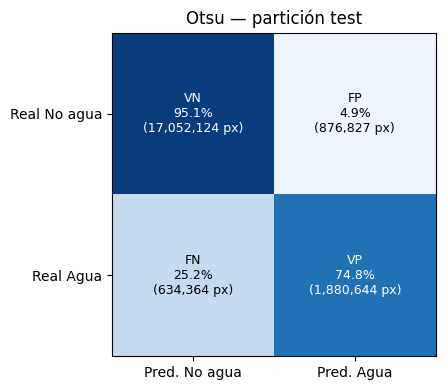

In [9]:
figura_matriz_confusion(acumuladores_otsu['test'].matriz_confusion(), 'Otsu — partición test',
                        DIR_FIGURAS / 'f4_matriz_confusion_otsu_test.png');
acumuladores_otsu['test'].tabla_por_evento()[['iou', 'f1', 'precision', 'recall', 'omision', 'comision']].round(3)

## Para traer a la conversación
Las tablas de las secciones **2**, **3** y **4**, la matriz de confusión y la tabla por evento.